# 1 · Data: where, when, what

Sentinel-1 land use / land cover segmentation, **Sentinel-1 as the only model input**. This notebook documents the
dataset: where the 600 places are, how balanced they are, what the radar input and the labels look like, and how
noisy the monthly labels are. All numbers are computed from the files in `data/tiles_v0/` (see `data/README.md`
for how they were downloaded from Google Earth Engine).

### How to read this notebook

The model can only be as good and as general as its training data, so this notebook is about the data, in the order
it was built: **which places** (1.1), **which radar images** (1.2), **which classes** (1.3), **how the data are
balanced** (1.4), **how good the labels are** (1.5), **one place in pictures** (1.6) and **every processing step on
one example** (1.7). Each step is explained in a "How and why" cell: what, why, how, how to read the output, what we
learned. Words in *italics* are in the glossary of notebook 00.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent                  # the s1-lulc folder
sys.path[:0] = [str(ROOT / "data"), str(ROOT / "train"), str(ROOT / "prototype")]
DATA, PREP, RUNS = ROOT / "data" / "tiles_v0", ROOT / "data" / "tiles_v0" / "prepared", ROOT / "train" / "runs"
from classes import CLASS_NAMES, DISPLAY_NAMES, CLASS_COLOURS, N_CLASSES, BUILT
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("project folder:", ROOT)

project folder: /home/jovyan/vault/s1-lulc


## 1.1 The 600 places

Places were drawn at random **stratified by world region × biome × settlement type × land cover** (`data/sample_tiles.py`), not
picked by hand, so the model sees villages in the Sahel as well as German cities. Towns and cities were also drawn
directly from GHSL urban areas, because random points almost never land in a city (Project Log, iteration 18).
Train / val / test are split by **5° geographic blocks**: test places are never next to training places.

In [2]:
tiles = pd.read_csv(DATA / "tiles.csv")
print(f"{len(tiles)} places, 2.56 km x 2.56 km each (256 x 256 pixels of 10 m)")
display(pd.crosstab(tiles.region, tiles.settlement, margins=True))
display(pd.crosstab(tiles.settlement, tiles.split, margins=True))

600 places, 2.56 km x 2.56 km each (256 x 256 pixels of 10 m)


settlement,city,none,town,village,All
region,,,,,
africa_mideast,16,24,23,29,92
asia_north,16,19,23,26,84
asia_south,18,24,24,28,94
europe,22,24,23,29,98
north_america,16,24,9,28,77
oceania,16,24,9,28,77
south_america,16,24,9,29,78
All,120,163,120,197,600


split,test,train,val,All
settlement,,,,
city,30,77,13,120
none,29,118,16,163
town,28,79,13,120
village,43,135,19,197
All,130,409,61,600


### How and why: choosing the places

**What.** The table lists how many of the 600 places lie in each world region and settlement type (city, town,
village, none), and how they are divided into train / validation / test.

**Why.** The project requirement: the model must work *anywhere*, not only where the training data came from. A model
trained on 20 German cities would learn "European roofs and European fields" and fail on mud-brick villages in Niger.
So the places must cover all continents, all climate zones (biomes), cities and empty land.

**How.** `data/sample_tiles.py` draws random points in Google Earth Engine, **stratified**: the world is cut into
groups (region × biome × settlement type × land cover) and points are drawn from each group, so rare groups (desert
towns, tropical cities) are not left out. Settlement type comes from the GHSL settlement model (EU JRC), biome from
RESOLVE Ecoregions, land cover from ESA WorldCover. Random points almost never fall into a city (cities cover < 1 %
of land), so 300 extra points were drawn directly inside GHSL towns and cities (cities 57 → 120).

**Splits.** Places are assigned to train / validation / test by **5° × 5° blocks** (about 550 km), not one by one.
Neighbouring places look alike (same crops, same building style); if the test place were next to a training place,
the test score would be too optimistic. With blocks, every test place is in a region the network has not seen.

**Reading the output.** Rows = regions, columns = settlement types, "All" = totals. The second table shows that each
settlement type appears in all three splits (409 train, 61 validation, 130 test places).

**What we learned.** The first version (300 places, random only) had too few cities; the learning curve (E1half,
notebook 02) showed that more places help (+2.4 mIoU points from doubling), so the dataset was doubled to 600.

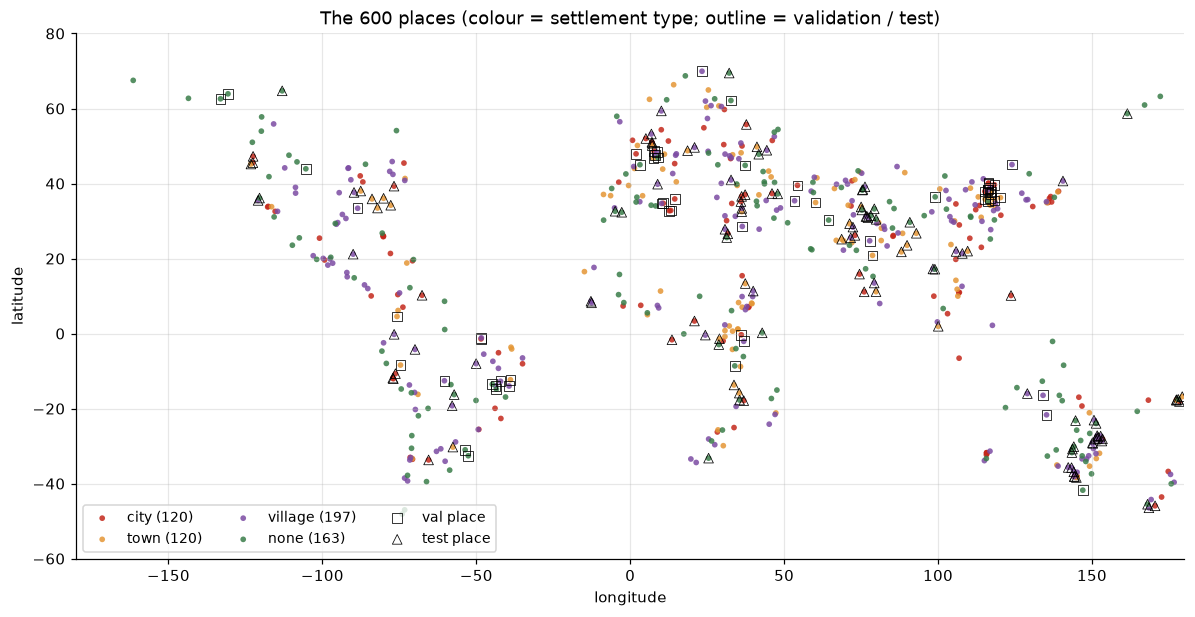

In [3]:
colours = {"city": "#c4281b", "town": "#e49635", "village": "#7b4ba3", "none": "#397d49"}
fig, ax = plt.subplots(figsize=(13, 6.2))
for s, c in colours.items():
    d = tiles[tiles.settlement == s]
    ax.scatter(d.lon, d.lat, s=14, c=c, label=f"{s} ({len(d)})", alpha=0.85, edgecolors="none")
for sp, m in [("val", "s"), ("test", "^")]:
    d = tiles[tiles.split == sp]
    ax.scatter(d.lon, d.lat, s=40, facecolors="none", edgecolors="k", linewidths=0.5, marker=m, label=f"{sp} place")
ax.set_xlim(-180, 180); ax.set_ylim(-60, 80); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.grid(alpha=0.3); ax.legend(loc="lower left", ncol=3, fontsize=9)
ax.set_title("The 600 places (colour = settlement type; outline = validation / test)")
plt.show()

**Reading the map.** Each dot is one place of 2.56 km × 2.56 km; colour = settlement type; squares / triangles mark
validation / test places. The places spread over every inhabited continent; deserts, rainforest, mountains and coasts
are included on purpose because they are the hard cases for radar. The biome table below counts places per biome (14
biomes from tundra to tropical forest).

In [4]:
display(tiles.biome_name.value_counts().rename("places").to_frame())

,places
biome_name,
Temperate broadleaf & mixed forests,127
Tropical moist broadleaf forests,65
Deserts & xeric shrublands,63
"Temperate grasslands, savannas & shrublands",60
"Tropical grasslands, savannas & shrublands",58
"Mediterranean forests, woodlands & scrub",58
Montane grasslands & shrublands,37
Tropical dry broadleaf forests,35
Temperate conifer forests,19


## 1.2 Sentinel-1 input: every raw scene of 2023

For every place, **every Sentinel-1 IW acquisition of 2023** was downloaded (no averaging), prepared in Earth Engine
with the recipe below. Every scene is one training sample, labelled with the map of its month.

Recipe: S1_GRD IW, border mask, terrain-flattened gamma0 (Vollrath 2020 volume model, GLO-30), dB
prepared places: 600 of 600 | scenes: 34981 | terrain flattened: True
normalisation (train scenes, dB): mean [-10.06 -17.49  -7.43] std [4.67 5.18 3.75]


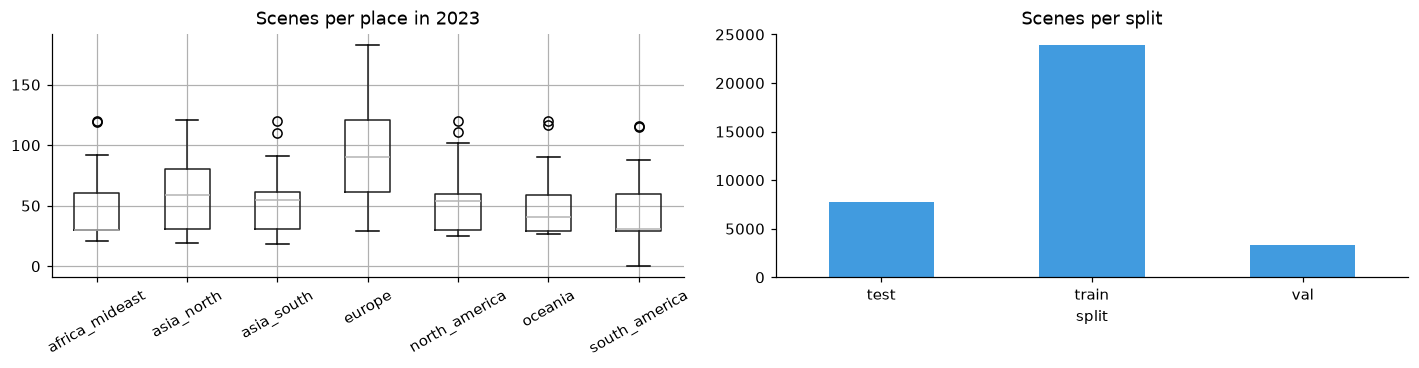

Europe has up to ~180 scenes per place (many overlapping orbits) vs ~30 elsewhere; training and test scores are
therefore weighted per PLACE, not per scene (Project Log, iteration 17).


In [5]:
import s1_composite
print("Recipe:", s1_composite.PREPROCESSING)
stats = json.loads((PREP / "stats.json").read_text())
idx = pd.read_csv(PREP / "index.csv"); ok = idx[idx.status == "ok"]
print(f"prepared places: {len(ok)} of {len(idx)} | scenes: {int(ok.scenes.sum())} | terrain flattened: {stats.get('terrain_flattened')}")
print("normalisation (train scenes, dB): mean", np.round(stats["mean"], 2), "std", np.round(stats["std"], 2))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ok.boxplot(column="scenes", by="region", ax=ax[0], rot=30); ax[0].set_title("Scenes per place in 2023"); ax[0].set_xlabel("")
ok.groupby("split").scenes.sum().plot.bar(ax=ax[1], rot=0, color="#419bdf"); ax[1].set_title("Scenes per split")
plt.suptitle(""); plt.tight_layout(); plt.show()
print("Europe has up to ~180 scenes per place (many overlapping orbits) vs ~30 elsewhere; training and test scores are")
print("therefore weighted per PLACE, not per scene (Project Log, iteration 17).")

### How and why: the radar input

**What.** For every place, every Sentinel-1 scene of 2023 was downloaded: about 58 per place on average, 34,981 in
total, each 256 × 256 pixels with 3 channels (VV, VH, VH − VV in dB).

**Why single scenes and not monthly averages?** (1) Many more training examples (35,000 instead of 7,200).
(2) Every scene has its own speckle and moisture, so the network learns to ignore day-to-day noise. (3) The prototype
can then use any number of scenes per month. An earlier version trained on monthly median composites (Project Log);
single scenes gave more stable results.

**How (the recipe).** In Earth Engine (`data/s1_composite.py`):
1. *S1_GRD* scenes in IW mode with both VV and VH, over the place, in 2023;
2. border noise masked (the scene edges are unreliable);
3. **terrain flattening** to γ⁰ with the Copernicus 30 m terrain model (Vollrath et al. 2020): removes the bright /
   dark effect of slopes; layover and shadow (steep terrain the radar cannot see) masked as *no data*;
4. conversion to dB, VH − VV computed, stored as whole numbers (dB × 100) to save space; −32768 = no data.

Slices of the same satellite pass (same date and orbit) are merged into one scene. Scenes covering < 50 % of the
place are dropped.

**Normalisation.** The network works best with inputs around 0 with spread 1, so each channel is standardised:
(value − mean) / std, with mean and std computed **from the training scenes only** (using test data here would leak
information). The printed numbers are these statistics.

**Reading the plots.** Left: scenes per place by region: Europe has up to ~180 (overlapping orbits), most other
places ~30. Right: scenes per split.

**What we learned.** Because Europe has 5× more scenes per place, a plain average over scenes would let Europe
dominate both training and test scores. So training draws and test scores are weighted **per place**, not per scene
(Project Log, iteration 17). Exporting dense European places first failed with Earth Engine memory errors; it was
fixed by reading the list of scenes first and building one scene at a time.

## 1.3 Classes and their distribution

Dynamic World's 9 classes are merged into **6 classes** that Sentinel-1 can tell apart (`data/classes.py`).

,Dynamic World class,our class
0,water,water
1,trees,trees
2,grass,grass & shrub
3,flooded veg.,grass & shrub
4,crops,crops
5,shrub & scrub,grass & shrub
6,built,built-up
7,bare,bare & snow
8,snow & ice,bare & snow


,train %,val %,test %
water,6.0,4.8,5.9
trees,21.0,15.5,23.7
grass & shrub,17.3,16.5,18.7
crops,19.0,19.5,16.6
built-up,21.9,25.2,23.0
bare & snow,14.7,18.5,12.0


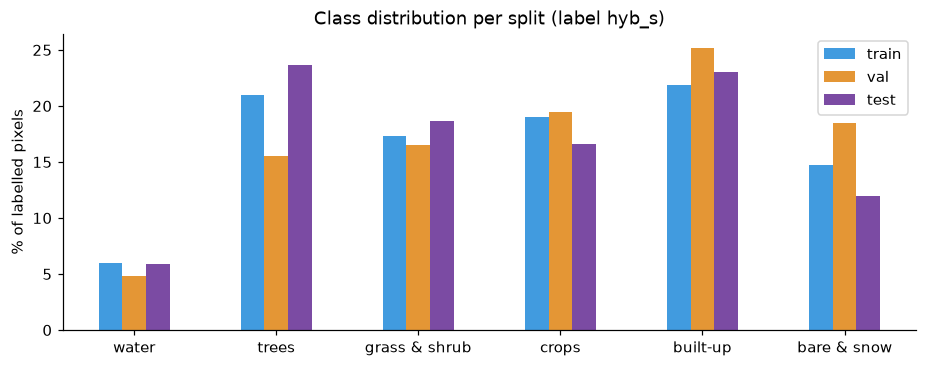

In [6]:
from classes import DW_TO_CLASS
dw_names = ["water", "trees", "grass", "flooded veg.", "crops", "shrub & scrub", "built", "bare", "snow & ice"]
display(pd.DataFrame({"Dynamic World class": dw_names, "our class": [DISPLAY_NAMES[c] for c in DW_TO_CLASS]}))
rows = {}
for sp in ["train", "val", "test"]:
    d = ok[ok.split == sp]
    px = np.array([d[f"px_hyb_s_{c}"].sum() for c in range(N_CLASSES)], float)
    rows[sp] = px / px.sum() * 100
dist = pd.DataFrame(rows, index=DISPLAY_NAMES).round(1)
display(dist.rename(columns=lambda c: f"{c} %"))
dist.plot.bar(figsize=(10, 3.5), rot=0, color=["#419bdf", "#e49635", "#7b4ba3"]); plt.ylabel("% of labelled pixels")
plt.title("Class distribution per split (label hyb_s)"); plt.show()

### How and why: 6 classes instead of 9

**What.** Dynamic World has 9 classes; we merge them into 6 (table above).

**Why.** A class should only exist if the input can distinguish it. C-band radar sees *structure and moisture*, not
colour:
* **grass + shrub & scrub + flooded vegetation → grass & shrub**: grass and low shrub give the same backscatter;
  flooded vegetation is rare and its labels are the least reliable;
* **bare + snow & ice → bare & snow**: snow is < 3 % of pixels and mostly seasonal; outside cold biomes, snow labels
  are removed altogether (they are usually cloud or bright sand misread by Dynamic World);
* **crops** stay separate: ploughing, growth and harvest change the backscatter month by month, which is useful;
* **built-up** stays: it is the class the prototype is about.

**Reading the output.** Class shares per split: grass & shrub, trees and crops dominate; built-up is a few percent,
water and bare less. The splits have similar mixes, so the test set represents the same kind of world as training.

**Why decided before training.** The merge follows from how radar works, so it was made before the first run (no
9-class model was trained). Classes the input cannot separate would only add speckled patches and month-to-month
flicker, and every flicker looks like change in the prototype.

## 1.4 Balance of the training data

Uniform sampling would let Europe (27% of scenes) and villages dominate. The **balanced sampler** (`train/balance.py`)
re-weights every scene so each world region and each settlement type gets an equal share of training draws, each place
counts equally regardless of its number of scenes, and rare classes get more weight in the loss.

# Training data balance report (label: `hyb_s`)

## 1. Tiles per settlement type and split

| settlement   |   test |   train |   val |   All |
|:-------------|-------:|--------:|------:|------:|
| city         |     30 |      77 |    13 |   120 |
| none         |     29 |     118 |    16 |   163 |
| town         |     28 |      79 |    13 |   120 |
| village      |     43 |     135 |    19 |   197 |
| All          |    130 |     409 |    61 |   600 |

## 2. Train tiles per region and settlement type

| region         |   city |   none |   town |   village |   All |
|:---------------|-------:|-------:|-------:|----------:|------:|
| africa_mideast |      9 |     16 |     18 |        21 |    64 |
| asia_north     |     10 |     13 |     15 |        20 |    58 |
| asia_south     |     14 |     17 |     13 |        19 |    63 |
| europe         |     11 |     18 |     19 |        19 |    67 |
| north_america  |     13 |     19 |      3 |        24 |    59 |
| oceania        |     10 |     16 |      6 |        12 |    44 |
| south_america  |     10 |     19 |      5 |        20 |    54 |
| All            |     77 |    118 |     79 |       135 |   409 |

Train tiles cover **14 of 14 biomes**.

## 3. Share of training draws, uniform vs balanced sampling

| axis       | group          |   raw_% |   balanced_% |   equal_share_% |
|:-----------|:---------------|--------:|-------------:|----------------:|
| region     | africa_mideast |    12.2 |         14.3 |            14.3 |
| region     | asia_north     |    16.3 |         14.3 |            14.3 |
| region     | asia_south     |    11.1 |         14.3 |            14.3 |
| region     | europe         |    27.3 |         14.3 |            14.3 |
| region     | north_america  |    13.3 |         14.3 |            14.3 |
| region     | oceania        |     9.2 |         14.3 |            14.3 |
| region     | south_america  |    10.6 |         14.3 |            14.3 |
| settlement | city           |    17.6 |         25   |            25   |
| settlement | none           |    26.1 |         25   |            25   |
| settlement | town           |    22.3 |         25   |            25   |
| settlement | village        |    34   |         25   |            25   |

## 4. Class shares (pixels the model sees)

Raw = uniform sampling. Balanced = expected share per draw with the balanced sampler. With loss = share of the loss signal once the class weights in the loss are added (what the model is pushed to learn). Val/test keep the real distribution on purpose.

| class       |   train_raw_% |   train_balanced_% |   train_with_loss_% |   val_% |   test_% |   train_tiles_with_class |
|:------------|--------------:|-------------------:|--------------------:|--------:|---------:|-------------------------:|
| water       |          6.28 |               7.6  |               11.45 |    4.31 |     4.86 |                      197 |
| trees       |         20.94 |              21.02 |               19.04 |   14.7  |    22.77 |                      344 |
| grass_shrub |         15.34 |              16.19 |               16.71 |   11.43 |    16.72 |                      360 |
| crops       |         18.72 |              16.01 |               16.62 |   15.94 |    16.85 |                      316 |
| built       |         22.22 |              26.47 |               21.37 |   31.56 |    24.92 |                      317 |
| bare_snow   |         16.49 |              12.71 |               14.81 |   22.07 |    13.87 |                      292 |

## 5. Diversity

- Train samples (single scenes): **19852** from **408** tiles
- Effective sample size with balanced sampling: **12785** (64% of samples). Below ~50% means a few samples are repeated a lot.

## 6. Warnings

- None. The training data is balanced on all three checks.


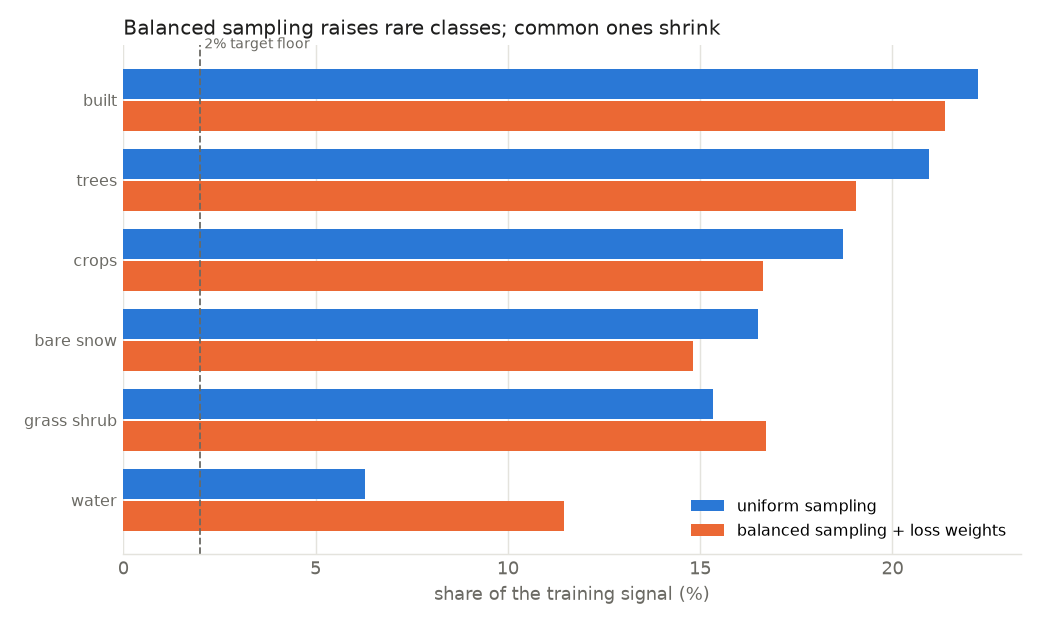

In [7]:
md = PREP / "balance_report.md"
if md.exists():
    display(Markdown(md.read_text()))
png = PREP / "balance_report.png"
if png.exists():
    display(Image(filename=str(png)))

### How and why: balancing what the network sees

**What.** The *balanced sampler* decides how often each training scene is drawn. The report shows the class shares
and the region / settlement shares before and after balancing.

**Why.** Without it the network would mostly see what is common in the data: European scenes (most scenes), rural
places (most places) and grass & trees (most pixels). It would get good at those and poor at African towns or
built-up areas, which are exactly what the prototype must find.

**How** (`train/balance.py`, three steps):
1. **class weight per scene**: scenes containing rare classes (built-up, water, bare) get a higher weight
   (inverse class share to the power 0.5, a mild boost);
2. **each place counts equally**: the weight is divided by the place's number of scenes, so 180 European scenes
   together count as much as 30 African ones;
3. **raking** (iterative proportional fitting): weights are scaled back and forth until every world region **and**
   every settlement type gets the same total share; extreme weights are capped at 10 × the median so the network
   does not see the same few scenes over and over.

The loss additionally gets mild **class weights** computed from what the sampler actually delivers.

**Reading the output.** "uniform" = every scene equally likely; "balanced" = what the network sees. Built-up and
water go up, grass and trees go down; every region gets 1/7 and every settlement type 1/4 of the draws. The
*effective sample size* (notebook 04) says how many independent scenes the weighted draw is worth: if it were very
small, the network would keep seeing the same scenes.

**What we learned.** The balance report flagged no warnings for the final 600 places.

## 1.5 How noisy are the monthly labels?

Labels come from Dynamic World (Sentinel-2) **per month**, so the model can learn change, plus Open Buildings roof
cover for small houses (hybrid). A pixel that changes class from one month to the next is mostly label noise
(clouds, leaf loss, harvest), not real land-use change. Seasonal smoothing (`hyb_s`) removes part of it.

In [8]:
flip = ok[["flip_dw", "flip_hyb", "flip_hyb_s"]].mean().rename({"flip_dw": "Dynamic World raw (E0)",
        "flip_hyb": "hybrid raw", "flip_hyb_s": "hybrid smoothed (E1)"})
display((flip * 100).round(1).rename("% pixels changing class month to month").to_frame())
built = ok.groupby("settlement")[["built_px_dw", "built_px_hyb"]].sum()
built["added by buildings %"] = (built.built_px_hyb / built.built_px_dw - 1) * 100
display(built.round(1))

,% pixels changing class month to month
Dynamic World raw (E0),15.8
hybrid raw,15.6
hybrid smoothed (E1),9.8


,built_px_dw,built_px_hyb,added by buildings %
settlement,,,
city,47818682,48552645,1.5
none,951955,958055,0.6
town,24560638,24672494,0.5
village,10060224,10167423,1.1


### How and why: cleaning the monthly labels

**What.** The first table: the share of pixels whose label changes from one month to the next, for three label
versions. The second: how many built-up pixels the building footprints add, per settlement type.

**Why it matters.** The prototype measures *change*. If the labels themselves change class every month (clouds,
leaves falling, harvest), the network learns that flicker and the prototype reports change that did not happen.
Real land-use change is below 1 % of pixels per year; Dynamic World flips 15.8 % of pixels every month.

**How.** Three steps (`data/prepare_data.py`):
1. **hybrid**: pixels where Open Buildings shows ≥ 15 % roof cover become built-up. Dynamic World is made from
   10 m optical images and misses small, scattered houses, especially in African villages;
2. **seasonal pair fix**: a pixel that is only ever "trees" or "grass & shrub" during the year (deciduous or dry
   forest that loses its leaves) gets its majority class in every month;
3. **3-month weighted vote**: each month's label = the most frequent class over the previous, current and next month
   (current month counts 1.5×). Single-month outliers disappear; changes that last stay.

**Reading the output.** Flicker 15.8 % (raw Dynamic World) → 9.8 % (hybrid smoothed): better, but still far above
real change, which is one reason the prototype needs its own smoothing and strict change rules. The building
footprints add the most built-up in villages and towns, where houses are small.

**What we learned.** Training on the smoothed hybrid label (E1) instead of raw Dynamic World (E0) gave the same
mIoU against the labels but steadier maps. An annual label (E1y: the yearly majority for every month) was tested
too: no better, and it cannot learn seasonal classes (notebook 02).

## 1.6 One example place

Radar input (VV backscatter of the scene used for each month), the raw Dynamic World label and the smoothed hybrid label.

t00295: city in europe (51.029, 7.056), Temperate broadleaf & mixed forests; 122 scenes


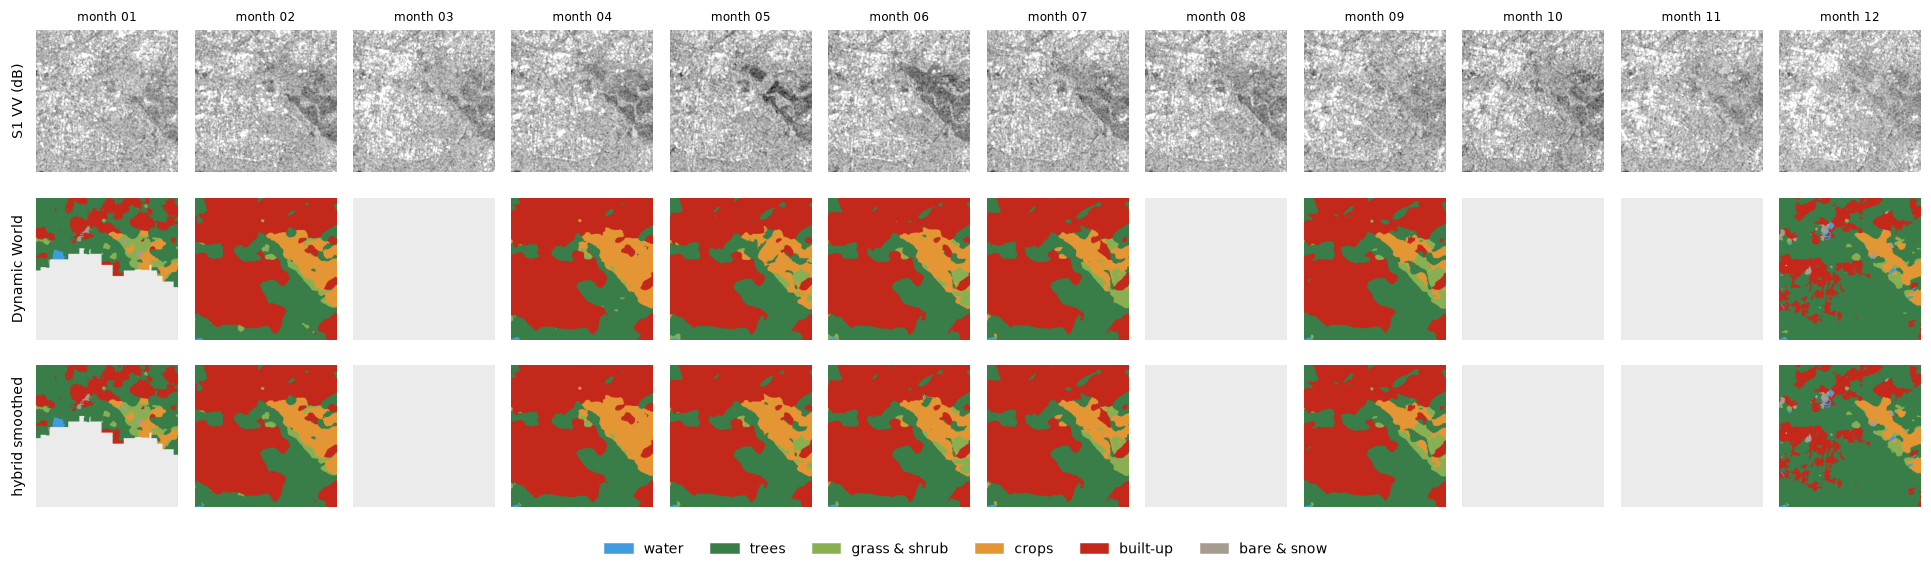

In [9]:
cand = ok[(ok.split == "test") & ok.settlement.isin(["town", "city"])].sort_values("scenes", ascending=False)
tid = (cand if len(cand) else ok).iloc[0].tile_id
z = np.load(PREP / f"{tid}.npz")
row = tiles.set_index("tile_id").loc[tid]
print(f"{tid}: {row.settlement} in {row.region} ({row.lat:.3f}, {row.lon:.3f}), {row.biome_name}; {len(z['s1'])} scenes")
from pipeline import colourise
best, months = z["best"], [f"{m + 1:02d}" for m in range(12)]
fig, axes = plt.subplots(3, 12, figsize=(18, 5.2))
for m in range(12):
    if best[m] >= 0:
        vv = z["s1"][best[m], 0].astype(float) / 100; vv[z["s1"][best[m], 0] == -32768] = np.nan
        axes[0, m].imshow(vv, cmap="gray", vmin=-25, vmax=0)
    axes[1, m].imshow(colourise(z["dw"][m])); axes[2, m].imshow(colourise(z["hyb_s"][m]))
    axes[0, m].set_title(f"month {months[m]}", fontsize=8)
for a in axes.ravel(): a.axis("off")
for r, t in enumerate(["S1 VV (dB)", "Dynamic World", "hybrid smoothed"]):
    axes[r, 0].text(-20, 128, t, rotation=90, va="center", ha="right", fontsize=9)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLOURS]
fig.legend(handles, DISPLAY_NAMES, loc="lower center", ncol=6, frameon=False, fontsize=9)
plt.tight_layout(rect=(0.02, 0.05, 1, 1)); plt.show()

### How to read the example place

Three rows × 12 months: the radar VV image of the scene used for that month, the raw Dynamic World label and the
smoothed hybrid label (the training target). Look for:
* **radar**: water and smooth surfaces dark, settlements bright and grainy; the grain is *speckle*;
* **Dynamic World**: grey "no label" months (clouds) and classes jumping between months;
* **hybrid smoothed**: the same areas, but steadier through the year and with more built-up where there are houses.

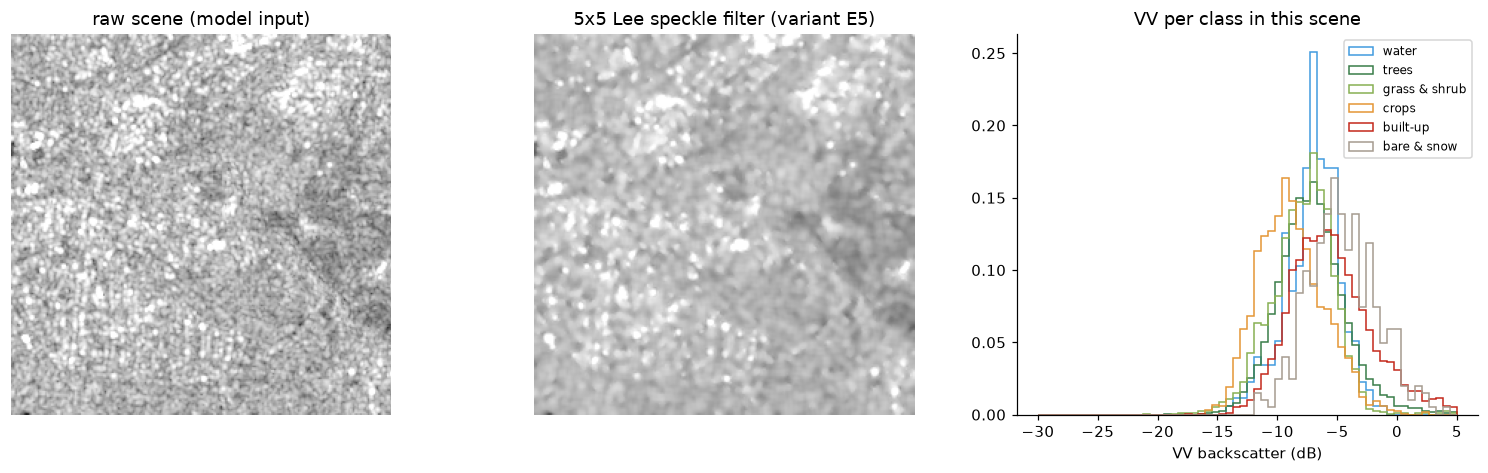

Water is dark (smooth surface), built-up is bright (double bounce from walls); vegetation classes overlap,
which is why grass, shrub, crops and bare ground are the hardest classes for a radar-only model.


In [10]:
from s1_composite import lee_filter_db
k = int(best[best >= 0][0])
raw = z["s1"][k]; lee = lee_filter_db(raw)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
for a, im, t in [(ax[0], raw, "raw scene (model input)"), (ax[1], lee, "5x5 Lee speckle filter (variant E5)")]:
    v = im[0].astype(float) / 100; v[im[0] == -32768] = np.nan
    a.imshow(v, cmap="gray", vmin=-25, vmax=0); a.set_title(t); a.axis("off")
lbl = z["hyb_s"][int(z["month"][k])]
for c in range(N_CLASSES):
    v = raw[0][(lbl == c) & (raw[0] != -32768)] / 100
    if v.size: ax[2].hist(v, bins=60, range=(-30, 5), histtype="step", color=CLASS_COLOURS[c], label=DISPLAY_NAMES[c], density=True)
ax[2].set_xlabel("VV backscatter (dB)"); ax[2].set_title("VV per class in this scene"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Water is dark (smooth surface), built-up is bright (double bounce from walls); vegetation classes overlap,")
print("which is why grass, shrub, crops and bare ground are the hardest classes for a radar-only model.")

### How and why: speckle and what each class looks like to radar

**What.** Left: one raw scene (what the network gets). Middle: the same scene after a 5 × 5 Lee speckle filter.
Right: the distribution of VV backscatter for each class in this scene.

**Why look at this.** It shows *why* some classes are easy and others hard. If two classes have the same backscatter
distribution, no network can separate them from one pixel; it has to use texture and context (neighbouring pixels),
which is what the convolution filters of a CNN do.

**How the Lee filter works.** For each pixel it looks at the 5 × 5 neighbourhood: in flat areas (low variance) it
replaces the pixel with the local mean (removes speckle); near edges (high variance) it keeps the pixel (keeps
detail). It is computed on linear power, not dB.

**What we learned.** Water (dark, left) and built-up (bright, right) are well separated. Trees, grass & shrub, crops
and bare overlap strongly, so they are the classes the model confuses (confusion matrix, notebook 02). The Lee
filter makes the image look cleaner but **did not improve the model** (variant E5: mIoU 0.493 vs 0.487, within
run-to-run noise, at 2.6× the processing time): a CNN already averages neighbouring pixels in its first layers, and
the filter also blurs small houses. Raw scenes were kept, and the speckle problem is solved over time instead (all
scenes of a month averaged in the prototype).

## 1.7 The data pipeline step by step

What the data looks like after each script, for the example place above:
**sampler → label download → scene download → label cleaning → prepared file → training sample**.

In [11]:
print("STEP 0 · sample_tiles.py -> tiles.csv (one row per place)")
display(tiles.head(3))
display(tiles[tiles.tile_id == tid].T.rename(columns=lambda c: tid))

STEP 0 · sample_tiles.py -> tiles.csv (one row per place)


,tile_id,region,lon,lat,biome,settlement,s1_months,s1_scenes,split,biome_name,utm_epsg,landcover
0,t00000,south_america,-42.126495,-12.724636,2,village,12,55,val,Tropical dry broadleaf forests,32723,NaN
1,t00001,north_america,-95.450491,29.154823,7,village,12,60,train,"Tropical grasslands, savannas & shrublands",32615,NaN
2,t00002,south_america,-60.353312,-12.571922,7,village,12,29,val,"Tropical grasslands, savannas & shrublands",32720,NaN


,t00295
tile_id,t00295
region,europe
lon,7.056267
lat,51.0288
biome,4
settlement,city
s1_months,12
s1_scenes,122
split,test
biome_name,Temperate broadleaf & mixed forests


### How and why: following one place through the whole pipeline

The next six cells show the **same place** after every script, so you can see exactly what each step changes:

| Step | Script | Output | What changes |
| --- | --- | --- | --- |
| 0 | `sample_tiles.py` | `tiles.csv` | a point + its region, biome, settlement type, split |
| 1 | `export_tiles.py` | `raw/<tile>.tif` | monthly labels downloaded on a 10 m UTM grid |
| 2 | `export_scenes.py` | `scenes/<tile>.npz` | every radar scene on exactly the same grid |
| 3 | `prepare_data.py` | (in memory) | labels cleaned: snow, 6 classes, buildings, smoothing |
| 4 | `prepare_data.py` | `prepared/<tile>.npz` | input + all label versions in one file |
| 5 | `balance.py`, `train.py` | tensors | normalised input + label + augmentation = a training sample |

**Why the same grid matters.** The label pixel (row 100, column 50) must describe exactly the ground under radar
pixel (100, 50). All downloads use the same UTM projection, the same 10 m pixel size and the same corner, computed
once per place, so nothing is resampled later.

STEP 1 · export_tiles.py -> raw/<tile>.tif (monthly labels from Earth Engine, 256 x 256 px, 10 m, UTM)


  73 bands, int16, 256 x 256 px, CRS EPSG:32632, pixel 10 m
  bands of one month: ['m07_VV', 'm07_VH', 'm07_VHVV', 'm07_N', 'm07_DW', 'm07_HYB'] + static BFRAC
  Dynamic World class ids in July: {np.int16(0): np.int64(64), np.int16(1): np.int64(20243), np.int16(2): np.int64(2216), np.int16(4): np.int64(5089), np.int16(5): np.int64(4), np.int16(6): np.int64(37920)}


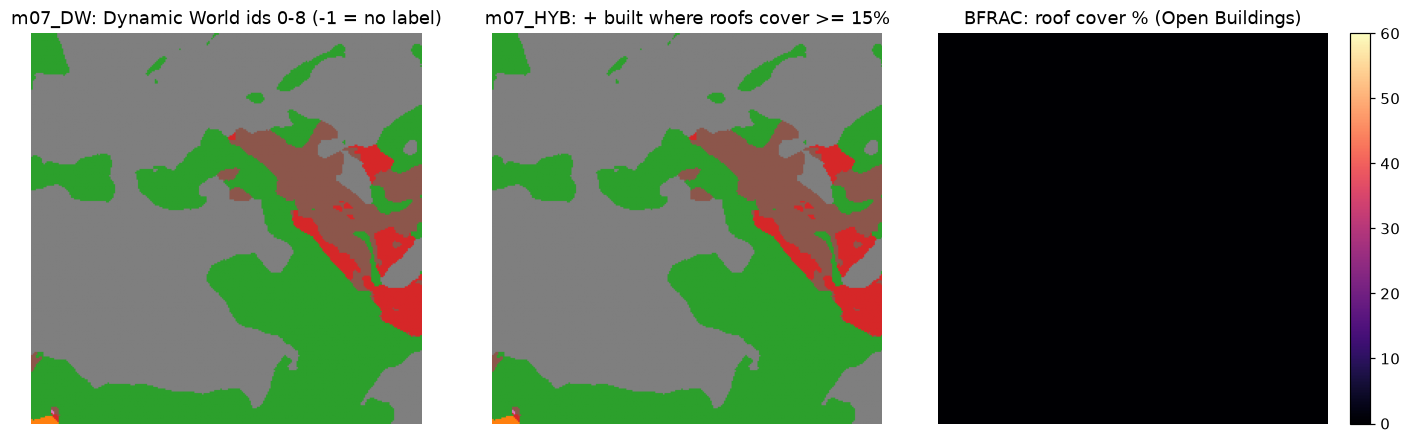

In [12]:
print("STEP 1 · export_tiles.py -> raw/<tile>.tif (monthly labels from Earth Engine, 256 x 256 px, 10 m, UTM)")
tif = DATA / "raw" / f"{tid}.tif"
if tif.exists():
    import rasterio
    with rasterio.open(tif) as src:
        print(f"  {src.count} bands, {src.dtypes[0]}, {src.width} x {src.height} px, CRS {src.crs}, pixel {src.res[0]:.0f} m")
        names = list(src.descriptions)
        if not all(names):          # Earth Engine GeoTIFFs carry no band names: use the fixed export order
            from export_tiles import all_band_names
            names = all_band_names()
        print("  bands of one month:", [n for n in names if n and n.startswith("m07_")], "+ static", names[-1])
        dw7 = src.read(names.index("m07_DW") + 1); hyb7 = src.read(names.index("m07_HYB") + 1)
        bfrac = src.read(names.index("BFRAC") + 1)
    print("  Dynamic World class ids in July:", dict(zip(*np.unique(dw7, return_counts=True))))
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    ax[0].imshow(dw7, cmap="tab10", vmin=-1, vmax=9); ax[0].set_title("m07_DW: Dynamic World ids 0-8 (-1 = no label)")
    ax[1].imshow(hyb7, cmap="tab10", vmin=-1, vmax=9); ax[1].set_title("m07_HYB: + built where roofs cover >= 15%")
    im = ax[2].imshow(bfrac, cmap="magma", vmin=0, vmax=60); ax[2].set_title("BFRAC: roof cover % (Open Buildings)")
    plt.colorbar(im, ax=ax[2], fraction=0.046)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("  (raw tif not found)")

**Reading step 1.** The GeoTIFF has one band per month and label version (e.g. `m07_DW` = July, Dynamic World;
`m07_HYB` = July, hybrid) plus static bands such as `BFRAC` (roof cover % from Open Buildings). The pictures show the
raw class ids (0–8, colours are only ids here), the hybrid label and the roof cover that turns pixels into built-up.

In [13]:
print("STEP 2 · export_scenes.py -> scenes/<tile>.npz (every raw Sentinel-1 acquisition of 2023)")
sc_path = DATA / "scenes" / f"{tid}.npz"
if sc_path.exists():
    sc = np.load(sc_path)
    display(pd.DataFrame({k: [str(sc[k].dtype), sc[k].shape] for k in sc.files}, index=["dtype", "shape"]).T)
    display(pd.DataFrame({"date": sc["date"], "orbit": sc["orbit"], "relative orbit": sc["rel_orbit"],
                          "coverage": np.round(sc["valid"], 3)}).head(10))
    v = sc["s1"][0]
    print("  stored as int16 = dB x 100 (-32768 = no data). Top-left 3 x 3 pixels of the first scene:")
    for b, name in enumerate(["VV", "VH", "VH-VV"]):
        print(f"    {name:6s}", v[b, :3, :3].tolist(), "->", np.round(v[b, :3, :3] / 100, 2).tolist(), "dB")
else:
    print("  (scenes file not found)")

STEP 2 · export_scenes.py -> scenes/<tile>.npz (every raw Sentinel-1 acquisition of 2023)


,dtype,shape
s1,int16,"(122, 3, 256, 256)"
date,<U10,"(122,)"
orbit,<U10,"(122,)"
rel_orbit,int16,"(122,)"
valid,float64,"(122,)"
flattened,bool,()


,date,orbit,relative orbit,coverage
0,2023-01-01,DESCENDING,139,1.0
1,2023-01-04,ASCENDING,15,1.0
2,2023-01-06,DESCENDING,37,1.0
3,2023-01-09,ASCENDING,88,1.0
4,2023-01-13,DESCENDING,139,1.0
5,2023-01-16,ASCENDING,15,1.0
6,2023-01-18,DESCENDING,37,1.0
7,2023-01-21,ASCENDING,88,1.0
8,2023-01-25,DESCENDING,139,1.0
9,2023-01-28,ASCENDING,15,1.0


  stored as int16 = dB x 100 (-32768 = no data). Top-left 3 x 3 pixels of the first scene:
    VV     [[-656, -803, -827], [-585, -525, -590], [-511, -399, -452]] -> [[-6.56, -8.03, -8.27], [-5.85, -5.25, -5.9], [-5.11, -3.99, -4.52]] dB
    VH     [[-1419, -1361, -1218], [-1158, -1085, -1204], [-910, -942, -1172]] -> [[-14.19, -13.61, -12.18], [-11.58, -10.85, -12.04], [-9.1, -9.42, -11.72]] dB
    VH-VV  [[-763, -558, -391], [-573, -561, -614], [-399, -542, -720]] -> [[-7.63, -5.58, -3.91], [-5.73, -5.61, -6.14], [-3.99, -5.42, -7.2]] dB


**Reading step 2.** One file per place with all its scenes: `s1` (scenes × 3 channels × 256 × 256), the date,
orbit direction (ascending / descending), relative orbit number and the share of the place covered (`valid`). The
printed 3 × 3 pixels show the storage trick: whole numbers = dB × 100, divided by 100 when read.

STEP 3 · prepare_data.py: label cleaning, one month and one pixel at every stage


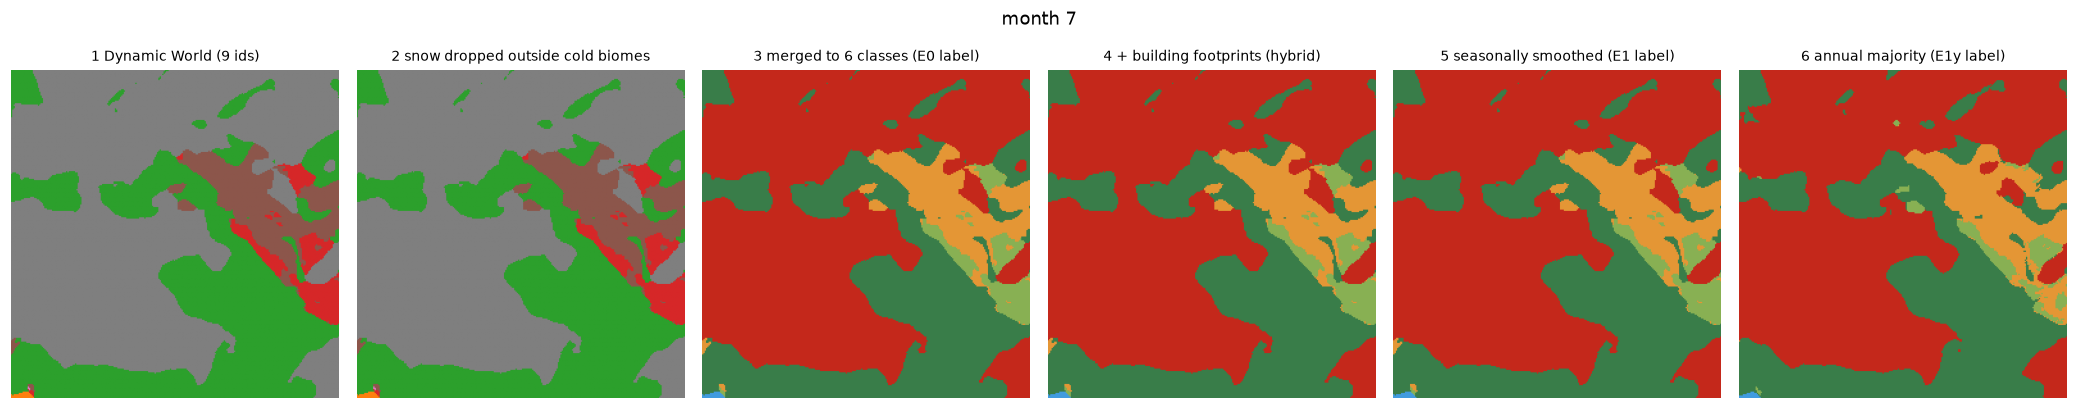

  The most 'flickering' pixel of this place (row 0, col 16) through the 12 months:


,month 1,month 2,month 3,month 4,month 5,month 6,month 7,month 8,month 9,month 10,month 11,month 12
1 Dynamic World (9 ids),trees,built,-,built,trees,built,trees,-,trees,-,-,trees
2 snow dropped outside cold biomes,trees,built,-,built,trees,built,trees,-,trees,-,-,trees
3 merged to 6 classes (E0 label),trees,built-up,-,built-up,trees,built-up,trees,-,trees,-,-,trees
4 + building footprints (hybrid),trees,built-up,-,built-up,trees,built-up,trees,-,trees,-,-,trees
5 seasonally smoothed (E1 label),trees,built-up,-,built-up,built-up,trees,trees,-,trees,-,-,trees
6 annual majority (E1y label),trees,trees,trees,trees,trees,trees,trees,trees,trees,trees,trees,trees


In [14]:
print("STEP 3 · prepare_data.py: label cleaning, one month and one pixel at every stage")
from prepare_data import read_tile, drop_snow, smooth_labels, annual_label
from classes import from_dw
if tif.exists():
    t = read_tile(tif)
    stages = {"1 Dynamic World (9 ids)": t["dw"]}
    s = drop_snow(t["dw"], int(row.biome)); stages["2 snow dropped outside cold biomes"] = s
    stages["3 merged to 6 classes (E0 label)"] = from_dw(s)
    h = from_dw(drop_snow(t["hyb"], int(row.biome))); stages["4 + building footprints (hybrid)"] = h
    stages["5 seasonally smoothed (E1 label)"] = smooth_labels(h)
    stages["6 annual majority (E1y label)"] = annual_label(h)
    m = 6
    fig, ax = plt.subplots(1, 6, figsize=(19, 3.6))
    for a, (k, v) in zip(ax, stages.items()):
        a.imshow(v[m], cmap="tab10", vmin=-1, vmax=9) if k.startswith(("1", "2")) else a.imshow(colourise(v[m]))
        a.set_title(k, fontsize=9); a.axis("off")
    plt.suptitle(f"month {m + 1}", y=1.02); plt.tight_layout(); plt.show()
    lab6 = stages["3 merged to 6 classes (E0 label)"]
    changes = (np.diff(lab6, axis=0) != 0).sum(0); yy, xx = np.unravel_index(changes.argmax(), changes.shape)
    seq = pd.DataFrame({k: [DISPLAY_NAMES[c] if (c >= 0 and not k.startswith(("1", "2"))) else (dw_names[c] if c >= 0 else "-")
                            for c in v[:, yy, xx]] for k, v in stages.items()}, index=[f"month {i + 1}" for i in range(12)]).T
    print(f"  The most 'flickering' pixel of this place (row {yy}, col {xx}) through the 12 months:")
    display(seq)

**Reading step 3.** Six versions of the same month: from raw Dynamic World ids to the smoothed hybrid label used
for training (E1) and the annual label (E1y). The table below follows the **most flickering pixel** of the place
through the 12 months: raw labels jump between classes; the smoothed version keeps one class or changes once.

In [15]:
print("STEP 4 · prepared/<tile>.npz: everything the training needs, aligned pixel by pixel")
display(pd.DataFrame({k: [str(z[k].dtype), z[k].shape] for k in z.files}, index=["dtype", "shape"]).T)
print("  scenes per month (n):", z["n"].tolist())
print("  scene used for each month's map (best):", z["best"].tolist())

STEP 4 · prepared/<tile>.npz: everything the training needs, aligned pixel by pixel


,dtype,shape
s1,int16,"(122, 3, 256, 256)"
n,int16,"(12,)"
dw,int8,"(12, 256, 256)"
hyb,int8,"(12, 256, 256)"
bfrac,uint8,"(256, 256)"
month,int8,"(122,)"
day,int8,"(122,)"
orbit,<U10,"(122,)"
valid,float64,"(122,)"
best,int32,"(12,)"


  scenes per month (n): [11, 9, 11, 9, 11, 10, 10, 10, 11, 10, 10, 10]
  scene used for each month's map (best): [5, 15, 24, 35, 45, 55, 65, 75, 86, 96, 106, 116]


**Reading step 4.** The prepared file contains everything training needs, aligned: `s1` (all scenes), `month` and
`day` of each scene, the label versions (`dw`, `hyb`, `hyb_s`, `hyb_y`; 12 months each), `n` = scenes per month,
`best` = the scene with the best coverage nearest mid-month (used for "one scene per month" evaluation).

STEP 5 · balance.py + train.py: from file to training sample


  81 training samples from this place (one per scene with enough labelled pixels):


,tile_id,sample,month,split,region,settlement,biome,c0,c1,c2,c3,c4,c5
0,t00295,0,0,test,europe,city,4,301,17661,2519,2262,8454,346
1,t00295,1,0,test,europe,city,4,301,17661,2519,2262,8454,346
2,t00295,2,0,test,europe,city,4,301,17661,2519,2262,8454,346
3,t00295,3,0,test,europe,city,4,301,17661,2519,2262,8454,346
4,t00295,4,0,test,europe,city,4,301,17661,2519,2262,8454,346


  input tensor x: (3, 256, 256) torch.float32;  label tensor y: (256, 256) torch.int64, values [-1, 0, 1, 2, 3, 4, 5] (-1 = ignored)


,raw dB mean,raw dB std,normalised mean,normalised std
VV,-6.77,3.46,0.71,0.74
VH,-13.42,3.31,0.79,0.64
VH-VV,-6.65,3.77,0.21,1.01


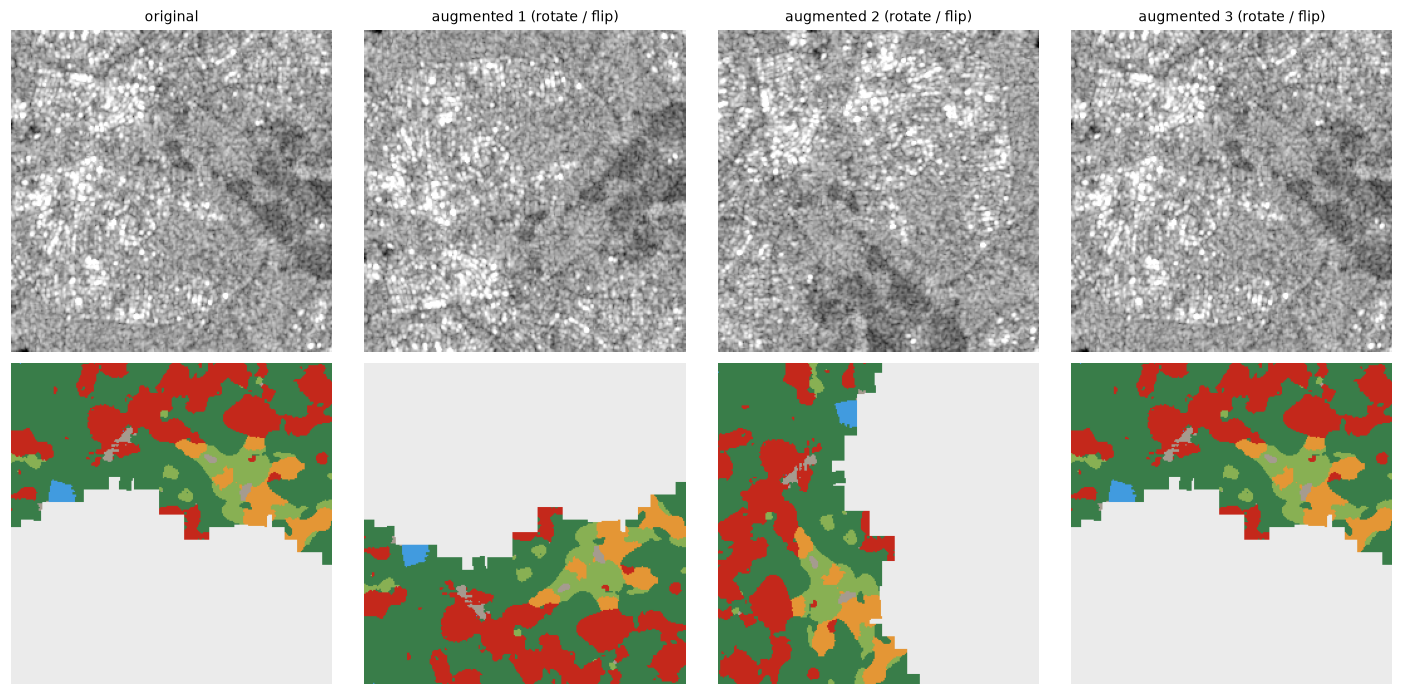

In [16]:
print("STEP 5 · balance.py + train.py: from file to training sample")
from balance import item_table, sample_weights
items = item_table(PREP, tiles[tiles.tile_id == tid].assign(biome=row.biome), "hyb_s")
print(f"  {len(items)} training samples from this place (one per scene with enough labelled pixels):")
display(items.head(5))
from train import TileMonths
ds = TileMonths(items.head(4), PREP, "hyb_s", stats["mean"], stats["std"], augment=False)
x, y = ds[0]
raw = z["s1"][items.iloc[0]["sample"]].astype(np.float32) / 100
stat = pd.DataFrame({"raw dB mean": raw.reshape(3, -1).mean(1), "raw dB std": raw.reshape(3, -1).std(1),
                     "normalised mean": x.reshape(3, -1).mean(1).numpy(), "normalised std": x.reshape(3, -1).std(1).numpy()},
                    index=["VV", "VH", "VH-VV"])
print(f"  input tensor x: {tuple(x.shape)} {x.dtype};  label tensor y: {tuple(y.shape)} {y.dtype}, values {sorted(set(y.unique().tolist()))} (-1 = ignored)")
display(stat.round(2))
ds_aug = TileMonths(items.head(1), PREP, "hyb_s", stats["mean"], stats["std"], augment=True)
fig, ax = plt.subplots(2, 4, figsize=(13, 6.4))
np.random.seed(3)
for j in range(4):
    xa, ya = ds_aug[0] if j else (x, y)
    ax[0, j].imshow(xa[0], cmap="gray", vmin=-2.5, vmax=2.5); ax[1, j].imshow(colourise(ya.numpy()))
    ax[0, j].set_title("original" if j == 0 else f"augmented {j} (rotate / flip)", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**Reading step 5.** `item_table` turns the place into training samples: one row per scene with enough labelled
pixels (≥ 20 %), with its month and class pixel counts (used for the sampling weights). `TileMonths` (the PyTorch
Dataset) turns one row into tensors: **x** = 3 × 256 × 256 floats (normalised: mean ≈ 0, std ≈ 1, as the table shows)
and **y** = 256 × 256 class ids, with −1 where there is no label or no radar data (these pixels are ignored by the
loss). The pictures show **augmentation**: during training each sample is randomly rotated by 0/90/180/270° and maybe
flipped; the label is rotated with it. A field looks the same from any direction, so this adds variety for free.
(Radiometric augmentation, random brightness shifts, was also tried as E6 and made results worse; notebook 02.)